In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load datasets
transactions = pd.read_csv("Data/transactions.csv")
budgets = pd.read_csv("Data/budgets.csv")
categories = pd.read_csv("Data/categories.csv")

print("Datasets loaded successfully!")

print("Transactions:", transactions.shape)
print("Budgets:", budgets.shape)
print("Categories:", categories.shape)

Datasets loaded successfully!
Transactions: (761, 6)
Budgets: (443, 6)
Categories: (15, 5)


In [2]:
import os

print("Current notebook directory:", os.getcwd())
print("\nFiles and folders here:")
print(os.listdir())



Current notebook directory: D:\Python_Projects\Financial-Data-Analysis

Files and folders here:
['.ipynb_checkpoints', 'anaconda_projects', 'Data', 'Financial_Data_Analysis.ipynb', 'Notebooks', 'README.md.txt', 'Reports']


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load datasets
transactions = pd.read_csv("Data/transactions.csv")
budgets = pd.read_csv("Data/budgets.csv")
categories = pd.read_csv("Data/categories.csv")

print("All datasets loaded successfully!")

print("Transactions:", transactions.shape)
print("Budgets:", budgets.shape)
print("Categories:", categories.shape)

All datasets loaded successfully!
Transactions: (761, 6)
Budgets: (443, 6)
Categories: (15, 5)


In [4]:
# Display the first 5 rows of each dataset

print("TRANSACTIONS DATASET")
display(transactions.head())

print("BUDGETS DATASET")
display(budgets.head())

print("CATEGORIES DATASET")
display(categories.head())

TRANSACTIONS DATASET


,id,user_id,category_id,amount,transaction_date,notes
0,1,105,9,27.11,2023-07-10 14:23:44,The account owner reported a repeat issue; the...
1,2,161,3,197.53,2022-07-07 17:23:42,The supplier confirmed the details and the ite...
2,3,142,15,815.08,2023-10-23 12:05:42,NaN
3,4,187,2,605.30,2023-12-11 20:26:06,The reviewer asked for a change and the delive...
4,5,165,1,151.67,2022-03-09 19:09:07,The supplier confirmed the details and the app...


BUDGETS DATASET


,id,user_id,category_id,budget_amount,start_date,end_date
0,1,127,13,1333.36,2023-02-28 13:51:36,2023-07-13 03:13:01
1,2,157,15,4781.92,2023-07-28 06:14:43,2023-07-01 20:52:42
2,3,194,11,526.48,2022-12-22 13:34:41,2023-07-25 19:07:18
3,4,4,6,219.72,2022-11-02 12:04:51,2022-12-23 12:06:47
4,5,88,13,1716.37,2023-04-27 13:15:13,2022-07-23 09:01:06


CATEGORIES DATASET


,id,name,created_at,expense_type,average_amount
0,1,Travel,2023-10-03 10:09:19,fixed,202.73
1,2,Subscriptions Clothing,2023-03-03 07:19:50,variable,296.43
2,3,Healthcare Fees,2023-03-30 11:54:22,fixed,372.67
3,4,Insurance,2022-04-03 08:20:49,variable,215.14
4,5,Transport,2022-03-26 09:12:58,fixed,973.22


In [5]:
print("TRANSACTIONS")
transactions.info()

print("\nBUDGETS")
budgets.info()

print("\nCATEGORIES")
categories.info()

TRANSACTIONS
<class 'pandas.DataFrame'>
RangeIndex: 761 entries, 0 to 760
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                761 non-null    int64  
 1   user_id           761 non-null    int64  
 2   category_id       761 non-null    int64  
 3   amount            761 non-null    float64
 4   transaction_date  761 non-null    str    
 5   notes             684 non-null    str    
dtypes: float64(1), int64(3), str(2)
memory usage: 87.0 KB

BUDGETS
<class 'pandas.DataFrame'>
RangeIndex: 443 entries, 0 to 442
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             443 non-null    int64  
 1   user_id        443 non-null    int64  
 2   category_id    443 non-null    int64  
 3   budget_amount  399 non-null    float64
 4   start_date     443 non-null    str    
 5   end_date       443 non-null    str    
dtype

In [6]:
# Check missing values
print("MISSING VALUES")
print("\nTransactions:")
print(transactions.isnull().sum())

print("\nBudgets:")
print(budgets.isnull().sum())

print("\nCategories:")
print(categories.isnull().sum())


# Check duplicate rows
print("\nDUPLICATE ROWS")
print("Transactions:", transactions.duplicated().sum())
print("Budgets:", budgets.duplicated().sum())
print("Categories:", categories.duplicated().sum())


# Check column names
print("\nCOLUMN NAMES")
print("Transactions:", transactions.columns.tolist())
print("Budgets:", budgets.columns.tolist())
print("Categories:", categories.columns.tolist())

MISSING VALUES

Transactions:
id                   0
user_id              0
category_id          0
amount               0
transaction_date     0
notes               77
dtype: int64

Budgets:
id                0
user_id           0
category_id       0
budget_amount    44
start_date        0
end_date          0
dtype: int64

Categories:
id                0
name              0
created_at        0
expense_type      0
average_amount    0
dtype: int64

DUPLICATE ROWS
Transactions: 0
Budgets: 0
Categories: 0

COLUMN NAMES
Transactions: ['id', 'user_id', 'category_id', 'amount', 'transaction_date', 'notes']
Budgets: ['id', 'user_id', 'category_id', 'budget_amount', 'start_date', 'end_date']
Categories: ['id', 'name', 'created_at', 'expense_type', 'average_amount']


In [7]:
# Convert date columns to datetime format
transactions["transaction_date"] = pd.to_datetime(
    transactions["transaction_date"], errors="coerce"
)

budgets["start_date"] = pd.to_datetime(
    budgets["start_date"], errors="coerce"
)

budgets["end_date"] = pd.to_datetime(
    budgets["end_date"], errors="coerce"
)

# Check invalid dates
print("Invalid transaction dates:", transactions["transaction_date"].isna().sum())
print("Invalid budget start dates:", budgets["start_date"].isna().sum())
print("Invalid budget end dates:", budgets["end_date"].isna().sum())

# Check financial amounts
print("\nNegative transaction amounts:", (transactions["amount"] < 0).sum())
print("Zero transaction amounts:", (transactions["amount"] == 0).sum())
print("Negative budget amounts:", (budgets["budget_amount"] < 0).sum())

# Check budget date ranges
print(
    "Budgets with start date after end date:",
    (budgets["start_date"] > budgets["end_date"]).sum()
)

Invalid transaction dates: 0
Invalid budget start dates: 0
Invalid budget end dates: 0

Negative transaction amounts: 0
Zero transaction amounts: 0
Negative budget amounts: 0
Budgets with start date after end date: 227


In [8]:
# Display budget records where the start date is after the end date
invalid_budgets = budgets[
    budgets["start_date"] > budgets["end_date"]
]

print("Number of affected records:", len(invalid_budgets))

invalid_budgets[
    ["id", "user_id", "category_id", "budget_amount",
     "start_date", "end_date"]
].head(10)

Number of affected records: 227


,id,user_id,category_id,budget_amount,start_date,end_date
1,2,157,15,4781.92,2023-07-28 06:14:43,2023-07-01 20:52:42
4,5,88,13,1716.37,2023-04-27 13:15:13,2022-07-23 09:01:06
6,7,87,2,1709.52,2023-10-12 14:03:53,2023-09-04 09:31:34
8,9,32,1,804.61,2023-10-12 20:37:37,2023-04-06 13:36:01
10,11,68,15,3524.77,2023-06-23 19:23:49,2022-01-05 22:47:02
11,12,68,6,1595.77,2023-04-16 23:05:47,2022-06-24 21:42:01
12,13,35,11,246.22,2022-04-08 19:18:37,2022-01-29 09:35:38
14,15,30,8,3624.38,2023-12-10 05:45:32,2023-09-09 08:24:24
15,16,59,10,3241.41,2023-09-23 12:13:17,2022-11-27 23:33:45
16,17,26,15,240.25,2023-10-17 01:53:35,2023-08-02 16:50:16


In [9]:
# Flag budgets with invalid date ranges
budgets["invalid_date_range"] = (
    budgets["start_date"] > budgets["end_date"]
)

print("Invalid budget date ranges:", budgets["invalid_date_range"].sum())
print("Valid budget date ranges:", (~budgets["invalid_date_range"]).sum())

Invalid budget date ranges: 227
Valid budget date ranges: 216


In [10]:
# Inspect budgets with missing amounts
missing_budgets = budgets[budgets["budget_amount"].isna()]

print("Missing budget amounts:", len(missing_budgets))

missing_budgets[
    ["id", "user_id", "category_id", "budget_amount",
     "start_date", "end_date"]
].head(10)

Missing budget amounts: 44


,id,user_id,category_id,budget_amount,start_date,end_date
23,24,33,5,NaN,2023-01-10 11:21:43,2023-02-16 12:26:51
43,44,52,6,NaN,2023-09-23 15:38:04,2023-05-27 05:17:59
61,62,24,11,NaN,2022-07-09 12:03:57,2022-09-25 22:59:29
66,67,192,4,NaN,2023-09-05 08:15:28,2022-04-05 21:26:33
86,87,36,14,NaN,2022-01-16 13:29:01,2022-04-05 11:21:59
114,115,198,4,NaN,2022-11-06 23:41:58,2023-11-17 12:56:04
115,116,80,13,NaN,2023-12-12 21:26:43,2023-06-26 09:44:35
127,128,161,6,NaN,2022-04-29 04:12:13,2023-05-10 10:14:51
139,140,91,15,NaN,2022-08-07 12:00:40,2023-04-15 22:10:07
156,157,120,5,NaN,2023-08-21 19:24:16,2023-01-28 18:13:42


In [11]:
# Check missing values before cleaning
print("Missing values before cleaning:")

print("\nTransactions:")
print(transactions.isnull().sum())

print("\nBudgets:")
print(budgets.isnull().sum())

print("\nCategories:")
print(categories.isnull().sum())

# Create working copies so the original dataframes remain unchanged
transactions_clean = transactions.copy()
budgets_clean = budgets.copy()
categories_clean = categories.copy()

print("\nWorking copies created successfully.")

Missing values before cleaning:

Transactions:
id                   0
user_id              0
category_id          0
amount               0
transaction_date     0
notes               77
dtype: int64

Budgets:
id                     0
user_id                0
category_id            0
budget_amount         44
start_date             0
end_date               0
invalid_date_range     0
dtype: int64

Categories:
id                0
name              0
created_at        0
expense_type      0
average_amount    0
dtype: int64

Working copies created successfully.


In [12]:
# Fill missing transaction notes
transactions_clean["notes"] = (
    transactions_clean["notes"].fillna("Not provided")
)

# Keep missing budget amounts as NaN
# Flag invalid budget date ranges
budgets_clean["invalid_date_range"] = (
    budgets_clean["start_date"] > budgets_clean["end_date"]
)

# Verify the changes
print("Missing transaction notes:",
      transactions_clean["notes"].isna().sum())

print("Missing budget amounts:",
      budgets_clean["budget_amount"].isna().sum())

print("Invalid budget date ranges:",
      budgets_clean["invalid_date_range"].sum())

Missing transaction notes: 0
Missing budget amounts: 44
Invalid budget date ranges: 227


In [13]:
# Get valid category IDs
valid_category_ids = set(categories_clean["id"])

# Check transactions referencing missing categories
invalid_transaction_categories = (
    ~transactions_clean["category_id"].isin(valid_category_ids)
).sum()

# Check budgets referencing missing categories
invalid_budget_categories = (
    ~budgets_clean["category_id"].isin(valid_category_ids)
).sum()

print("Transactions with invalid category IDs:",
      invalid_transaction_categories)

print("Budgets with invalid category IDs:",
      invalid_budget_categories)

Transactions with invalid category IDs: 0
Budgets with invalid category IDs: 0


In [14]:
# Inspect category names
print("Category names:")
print(categories_clean["name"].sort_values().to_list())

print("\nDuplicate category names:",
      categories_clean["name"].duplicated().sum())

print("\nUnique expense types:")
print(categories_clean["expense_type"].unique())

Category names:
['Clothing Miscellaneous', 'Dining Travel', 'Healthcare Fees', 'Insurance', 'Rent Miscellaneous', 'Repairs Taxes', 'Subscriptions', 'Subscriptions Clothing', 'Taxes Dining', 'Transport', 'Travel', 'Travel', 'Travel Healthcare', 'Travel Repairs', 'Utilities Groceries']

Duplicate category names: 1

Unique expense types:
<ArrowStringArray>
['fixed', 'variable', 'discretionary']
Length: 3, dtype: str


In [15]:
# Display duplicate category names
duplicate_categories = categories_clean[
    categories_clean["name"].duplicated(keep=False)
].sort_values("name")

duplicate_categories

,id,name,created_at,expense_type,average_amount
0,1,Travel,2023-10-03 10:09:19,fixed,202.73
8,9,Travel,2022-04-08 09:33:04,fixed,571.99


In [16]:
# Count categories by expense type
print("Expense type distribution:")
print(categories_clean["expense_type"].value_counts())

# Summarize average amounts by expense type
print("\nAverage amount by expense type:")
print(
    categories_clean.groupby("expense_type")["average_amount"]
    .agg(["count", "mean", "min", "max"])
    .round(2)
)

Expense type distribution:
expense_type
fixed            7
variable         4
discretionary    4
Name: count, dtype: int64

Average amount by expense type:
               count    mean     min     max
expense_type                                
discretionary      4  246.18   16.81  650.53
fixed              7  517.27   58.57  973.22
variable           4  319.64  213.50  553.49


In [17]:
# Join transactions with category information
transactions_analysis = transactions_clean.merge(
    categories_clean[["id", "name", "expense_type"]],
    left_on="category_id",
    right_on="id",
    how="left",
    suffixes=("", "_category")
)

# Summarize spending by category
category_spending = (
    transactions_analysis
    .groupby("name")["amount"]
    .agg(["sum", "mean", "count"])
    .sort_values("sum", ascending=False)
    .round(2)
)

category_spending.columns = [
    "Total Spending", "Average Transaction", "Transaction Count"
]

category_spending

,Total Spending,Average Transaction,Transaction Count
name,,,
Travel,37667.01,321.94,117
Travel Repairs,22760.77,367.11,62
Transport,21638.62,360.64,60
Healthcare Fees,20282.43,349.70,58
Subscriptions,18961.37,364.64,52
Travel Healthcare,18735.41,328.69,57
Subscriptions Clothing,18374.73,382.81,48
Utilities Groceries,16513.74,337.02,49
Insurance,16512.26,358.96,46


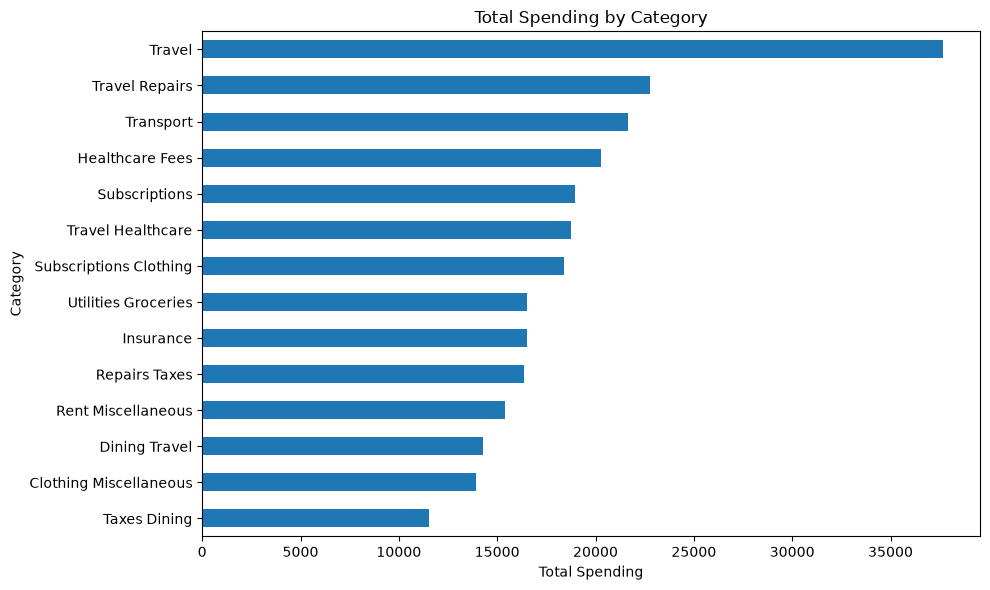

In [18]:
# Plot total spending by category
category_spending["Total Spending"].sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Total Spending by Category"
)

plt.xlabel("Total Spending")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

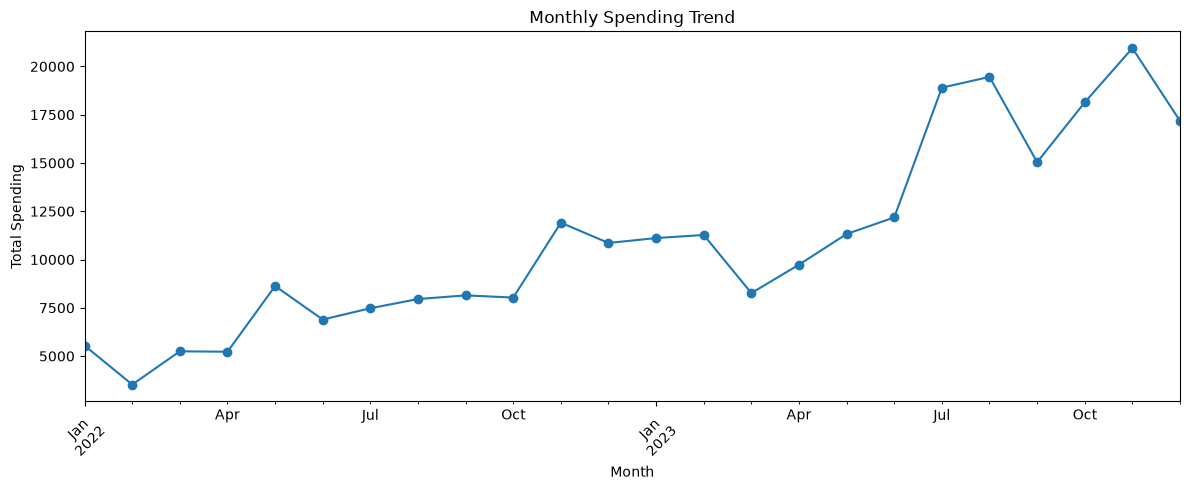

In [19]:
# Extract the transaction month
transactions_analysis["month"] = (
    transactions_analysis["transaction_date"].dt.to_period("M")
)

# Calculate monthly spending
monthly_spending = (
    transactions_analysis
    .groupby("month")["amount"]
    .sum()
)

# Plot monthly spending
monthly_spending.plot(
    kind="line",
    figsize=(12, 5),
    marker="o",
    title="Monthly Spending Trend"
)

plt.xlabel("Month")
plt.ylabel("Total Spending")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [20]:
# Merge transactions with expense types
expense_type_analysis = transactions_clean.merge(
    categories_clean[["id", "expense_type"]],
    left_on="category_id",
    right_on="id",
    how="left",
    suffixes=("", "_category")
)

# Calculate spending by expense type
type_spending = (
    expense_type_analysis
    .groupby("expense_type")["amount"]
    .agg(["sum", "mean", "count"])
    .sort_values("sum", ascending=False)
    .round(2)
)

type_spending.columns = [
    "Total Spending",
    "Average Transaction",
    "Transaction Count"
]

type_spending

,Total Spending,Average Transaction,Transaction Count
expense_type,,,
fixed,126457.04,352.25,359
variable,71590.54,357.95,200
discretionary,64936.15,321.47,202


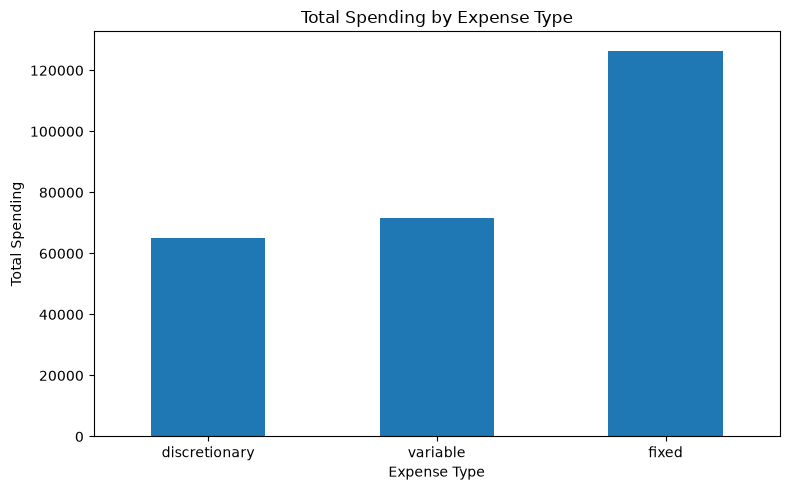

In [21]:
type_spending["Total Spending"].sort_values().plot(
    kind="bar",
    figsize=(8, 5),
    title="Total Spending by Expense Type"
)

plt.xlabel("Expense Type")
plt.ylabel("Total Spending")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [22]:
# Count valid and invalid budget records
print("Total budget records:", len(budgets_clean))

print(
    "Valid date ranges:",
    (~budgets_clean["invalid_date_range"]).sum()
)

print(
    "Missing budget amounts:",
    budgets_clean["budget_amount"].isna().sum()
)

print(
    "Records with valid dates and amounts:",
    (
        (~budgets_clean["invalid_date_range"])
        & budgets_clean["budget_amount"].notna()
    ).sum()
)

Total budget records: 443
Valid date ranges: 216
Missing budget amounts: 44
Records with valid dates and amounts: 197


In [23]:
# Keep budgets with valid date ranges and amounts
valid_budgets = budgets_clean[
    (~budgets_clean["invalid_date_range"])
    & budgets_clean["budget_amount"].notna()
].copy()

# Confirm the cleaned dataset
print("Usable budget records:", len(valid_budgets))

print("\nDate range:")
print("Earliest start:", valid_budgets["start_date"].min())
print("Latest end:", valid_budgets["end_date"].max())

print("\nMissing budget amounts:", valid_budgets["budget_amount"].isna().sum())
print(
    "Invalid date ranges:",
    (valid_budgets["start_date"] > valid_budgets["end_date"]).sum()
)

Usable budget records: 197

Date range:
Earliest start: 2022-01-03 14:27:17
Latest end: 2023-12-28 23:10:43

Missing budget amounts: 0
Invalid date ranges: 0


In [24]:
# Match transactions to budgets by user and category
budget_comparison = valid_budgets.merge(
    transactions_clean,
    on=["user_id", "category_id"],
    how="left",
    suffixes=("_budget", "_transaction")
)

# Keep transactions within each budget's date range
budget_comparison = budget_comparison[
    (budget_comparison["transaction_date"] >= budget_comparison["start_date"])
    & (budget_comparison["transaction_date"] <= budget_comparison["end_date"])
]

# Calculate spending against each budget
budget_summary = (
    budget_comparison
    .groupby(["id_budget", "user_id", "category_id", "budget_amount"])
    .agg(actual_spending=("amount", "sum"))
    .reset_index()
)

budget_summary["budget_difference"] = (
    budget_summary["budget_amount"] - budget_summary["actual_spending"]
)

budget_summary["status"] = np.where(
    budget_summary["actual_spending"] > budget_summary["budget_amount"],
    "Over Budget",
    "Within Budget"
)

budget_summary.head(10)

,id_budget,user_id,category_id,budget_amount,actual_spending,budget_difference,status
0,31,53,1,3529.60,395.80,3133.80,Within Budget
1,33,85,9,177.18,477.39,-300.21,Over Budget
2,48,91,10,2333.43,614.95,1718.48,Within Budget
3,69,112,1,2169.95,252.22,1917.73,Within Budget
4,70,41,14,153.15,407.48,-254.33,Over Budget
5,83,92,15,628.29,617.49,10.80,Within Budget
6,131,180,7,777.11,19.42,757.69,Within Budget
7,150,99,3,1555.16,877.24,677.92,Within Budget
8,162,86,6,325.31,17.55,307.76,Within Budget
9,219,14,1,1456.24,799.64,656.60,Within Budget


In [25]:
print("Category IDs:")
print(sorted(categories_clean["id"].unique()))

print("\nBudget category IDs:")
print(sorted(valid_budgets["category_id"].unique()))

print("\nTransaction category IDs:")
print(sorted(transactions_clean["category_id"].unique()))

Category IDs:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15)]

Budget category IDs:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15)]

Transaction category IDs:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15)]


In [26]:
print("Budgets compared:", len(budget_summary))

print("\nBudget status:")
print(budget_summary["status"].value_counts())

print("\nTotal budget amount:",
      round(budget_summary["budget_amount"].sum(), 2))

print("Total actual spending:",
      round(budget_summary["actual_spending"].sum(), 2))

print("Total budget remaining:",
      round(budget_summary["budget_difference"].sum(), 2))

Budgets compared: 22

Budget status:
status
Within Budget    18
Over Budget       4
Name: count, dtype: int64

Total budget amount: 40083.85
Total actual spending: 9438.5
Total budget remaining: 30645.35


In [27]:
# Count transactions matching each valid budget's user and category
budget_matches = valid_budgets.merge(
    transactions_clean,
    on=["user_id", "category_id"],
    how="left",
    suffixes=("_budget", "_transaction")
)

# Count matches before applying date filters
matched_pairs = budget_matches[
    budget_matches["transaction_date"].notna()
]

print("Valid budgets:", len(valid_budgets))
print("Budgets with matching user/category transactions:",
      matched_pairs[["id_budget", "user_id", "category_id"]]
      .drop_duplicates().shape[0])

Valid budgets: 197
Budgets with matching user/category transactions: 46


In [28]:
# Keep transactions within each budget's date range
in_period = budget_matches[
    budget_matches["transaction_date"].notna()
    & (budget_matches["transaction_date"] >= budget_matches["start_date"])
    & (budget_matches["transaction_date"] <= budget_matches["end_date"])
]

# Calculate spending for matching budget periods
period_spending = (
    in_period.groupby("id_budget")["amount"]
    .sum()
)

# Add spending back to every valid budget
budget_summary_all = valid_budgets.copy()

budget_summary_all["actual_spending"] = (
    budget_summary_all["id"].map(period_spending).fillna(0)
)

budget_summary_all["budget_difference"] = (
    budget_summary_all["budget_amount"]
    - budget_summary_all["actual_spending"]
)

budget_summary_all["status"] = np.where(
    budget_summary_all["actual_spending"]
    > budget_summary_all["budget_amount"],
    "Over Budget",
    "Within Budget"
)

print("Budgets analyzed:", len(budget_summary_all))
print("\nBudget status:")
print(budget_summary_all["status"].value_counts())

Budgets analyzed: 197

Budget status:
status
Within Budget    193
Over Budget        4
Name: count, dtype: int64


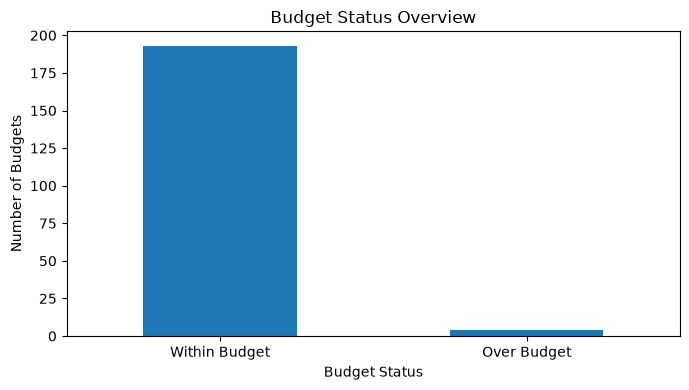

In [29]:
budget_status_counts = budget_summary_all["status"].value_counts()

budget_status_counts.plot(
    kind="bar",
    figsize=(7, 4),
    title="Budget Status Overview"
)

plt.xlabel("Budget Status")
plt.ylabel("Number of Budgets")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [30]:
total_spending = transactions_clean["amount"].sum()
average_transaction = transactions_clean["amount"].mean()
highest_transaction = transactions_clean["amount"].max()
lowest_transaction = transactions_clean["amount"].min()

print(f"Total Spending: ₹{total_spending:,.2f}")
print(f"Average Transaction: ₹{average_transaction:,.2f}")
print(f"Highest Transaction: ₹{highest_transaction:,.2f}")
print(f"Lowest Transaction: ₹{lowest_transaction:,.2f}")
print(f"Total Transactions: {len(transactions_clean)}")
print(f"Budgets Over Budget: {(budget_summary_all['status'] == 'Over Budget').sum()}")

Total Spending: ₹262,983.73
Average Transaction: ₹345.58
Highest Transaction: ₹998.78
Lowest Transaction: ₹1.00
Total Transactions: 761
Budgets Over Budget: 4


In [31]:
# Key Financial Insights

total_spending = transactions_clean["amount"].sum()
average_transaction = transactions_clean["amount"].mean()
total_transactions = len(transactions_clean)

top_category = category_spending["Total Spending"].idxmax()
top_category_spending = category_spending["Total Spending"].max()

highest_month = monthly_spending.idxmax()
lowest_month = monthly_spending.idxmin()

fixed_spending = type_spending.loc["fixed", "Total Spending"]
variable_spending = type_spending.loc["variable", "Total Spending"]
discretionary_spending = type_spending.loc["discretionary", "Total Spending"]

print("========== FINANCIAL INSIGHTS ==========")
print(f"Total Spending: ₹{total_spending:,.2f}")
print(f"Total Transactions: {total_transactions}")
print(f"Average Transaction: ₹{average_transaction:,.2f}")
print(f"Highest Spending Category: {top_category}")
print(f"Spending in Top Category: ₹{top_category_spending:,.2f}")
print(f"Highest Spending Month: {highest_month}")
print(f"Lowest Spending Month: {lowest_month}")
print(f"Fixed Expenses: ₹{fixed_spending:,.2f}")
print(f"Variable Expenses: ₹{variable_spending:,.2f}")
print(f"Discretionary Expenses: ₹{discretionary_spending:,.2f}")

========== FINANCIAL INSIGHTS ==========
Total Spending: ₹262,983.73
Total Transactions: 761
Average Transaction: ₹345.58
Highest Spending Category: Travel
Spending in Top Category: ₹37,667.01
Highest Spending Month: 2023-11
Lowest Spending Month: 2022-02
Fixed Expenses: ₹126,457.04
Variable Expenses: ₹71,590.54
Discretionary Expenses: ₹64,936.15


In [32]:
import os

os.makedirs("Reports", exist_ok=True)

transactions_clean.to_csv(
    "Reports/cleaned_transactions.csv", index=False
)

budgets_clean.to_csv(
    "Reports/cleaned_budgets.csv", index=False
)

categories_clean.to_csv(
    "Reports/cleaned_categories.csv", index=False
)

print("Cleaned datasets exported successfully!")
print("Location: Reports/")

Cleaned datasets exported successfully!
Location: Reports/


In [33]:
report = f"""
# Financial Data Analysis Report

## 1. Project Overview
This project analyzes financial transactions, budgets, and expense categories
to identify spending patterns and evaluate budget performance.

## 2. Dataset Summary
- Total transactions: {len(transactions_clean)}
- Total budget records: {len(budgets_clean)}
- Total expense categories: {len(categories_clean)}

## 3. Key Financial Metrics
- Total spending: ₹{transactions_clean['amount'].sum():,.2f}
- Average transaction: ₹{transactions_clean['amount'].mean():,.2f}
- Highest transaction: ₹{transactions_clean['amount'].max():,.2f}
- Lowest transaction: ₹{transactions_clean['amount'].min():,.2f}

## 4. Key Findings
- Highest-spending category: {top_category}
- Spending in that category: ₹{top_category_spending:,.2f}
- Highest-spending month: {highest_month}
- Lowest-spending month: {lowest_month}
- Fixed expenses: ₹{fixed_spending:,.2f}
- Variable expenses: ₹{variable_spending:,.2f}
- Discretionary expenses: ₹{discretionary_spending:,.2f}

## 5. Budget Analysis
- Valid budgets analyzed: {len(budget_summary_all)}
- Within budget: {(budget_summary_all['status'] == 'Within Budget').sum()}
- Over budget: {(budget_summary_all['status'] == 'Over Budget').sum()}

Note: Budgets without matching transactions during their date ranges were
treated as having zero observed spending. Budget results should therefore
be interpreted cautiously.

## 6. Conclusion
The analysis identifies spending patterns across categories, months, and
expense types. These findings can support better budgeting and financial
planning. Further analysis should investigate missing budget amounts and
inconsistent budget date ranges.
"""

with open("Reports/Financial_Analysis_Report.md", "w", encoding="utf-8") as file:
    file.write(report)

print("Financial analysis report created successfully!")

Financial analysis report created successfully!
